In [ ]:
!kaggle datasets download -d puneet6060/intel-image-classification

Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:03<00:00, 114MB/s]



In [ ]:
from zipfile import ZipFile

with ZipFile("intel-image-classification.zip", "r") as zip_ref:
    zip_ref.extractall("/content/intel_dataset")

print("Dataset extracted!")

Dataset extracted!


In [ ]:
#import libraries

import os
import shutil
import random

random.seed(42)

source = "/content/intel_dataset/seg_train/seg_train"
destination = "/content/final_dataset"

classes = ["forest", "glacier", "mountain", "sea"]

if os.path.exists(destination):
    shutil.rmtree(destination)

for cls in classes:

    src = os.path.join(source, cls)

    train_dst = os.path.join(destination, "train", cls)
    test_dst = os.path.join(destination, "test", cls)

    os.makedirs(train_dst, exist_ok=True)
    os.makedirs(test_dst, exist_ok=True)

    images = [img for img in os.listdir(src)
              if img.lower().endswith((".jpg",".jpeg",".png"))]

    random.shuffle(images)

    # 500 train
    train_imgs = images[:500]

    # 100 test
    test_imgs = images[500:600]

    for img in train_imgs:
        shutil.copy(os.path.join(src,img),
                    os.path.join(train_dst,img))

    for img in test_imgs:
        shutil.copy(os.path.join(src,img),
                    os.path.join(test_dst,img))

print("Done!")

Done!


In [ ]:
#organise dataset into train and test

import os
import torch
import timm
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch import nn, optim

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
train_dir = "/content/final_dataset/train"
test_dir = "/content/final_dataset/test"

In [ ]:
#image preprocessing and  data augmentation

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

In [ ]:
#load dataset

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

In [ ]:
#Display Dataset Classes


print("Classes:", train_dataset.classes)
print("Class Mapping:", train_dataset.class_to_idx)

print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))

Classes: ['forest', 'glacier', 'mountain', 'sea']
Class Mapping: {'forest': 0, 'glacier': 1, 'mountain': 2, 'sea': 3}
Training Images: 2000
Testing Images: 400


In [ ]:
#Create DataLoaders for Training, Validation and Testing


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
#Build HRNet Image Classification Model

model = timm.create_model(
    "hrnet_w18",
    pretrained=True,
    num_classes=4
)

model = model.cuda()

model.safetensors: reconstructing file:   0%|          |  0.00B / 85.6MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
#loss function

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print(device)

cuda


In [ ]:
num_epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

Epoch 1/5 | Loss: 0.4165 | Accuracy: 85.75%
Epoch 2/5 | Loss: 0.1621 | Accuracy: 94.50%
Epoch 3/5 | Loss: 0.0886 | Accuracy: 97.15%
Epoch 4/5 | Loss: 0.0996 | Accuracy: 96.45%
Epoch 5/5 | Loss: 0.0706 | Accuracy: 98.05%


In [ ]:
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

In [ ]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
f1 = f1_score(all_labels, all_predictions, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8975
Precision: 0.9024
Recall   : 0.8975
F1 Score : 0.8948


<Figure size 800x800 with 0 Axes>

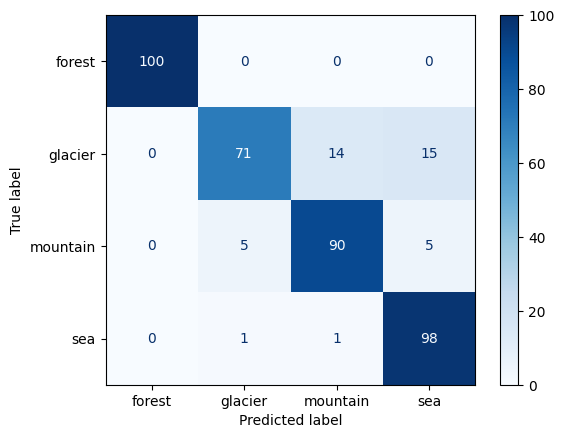

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

plt.figure(figsize=(8,8))
disp.plot(cmap="Blues")
plt.show()

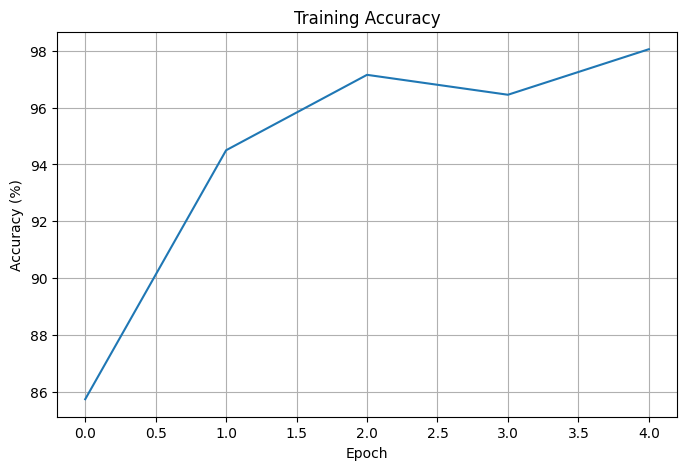

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_accuracies)

plt.title("Training Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.grid(True)

plt.show()

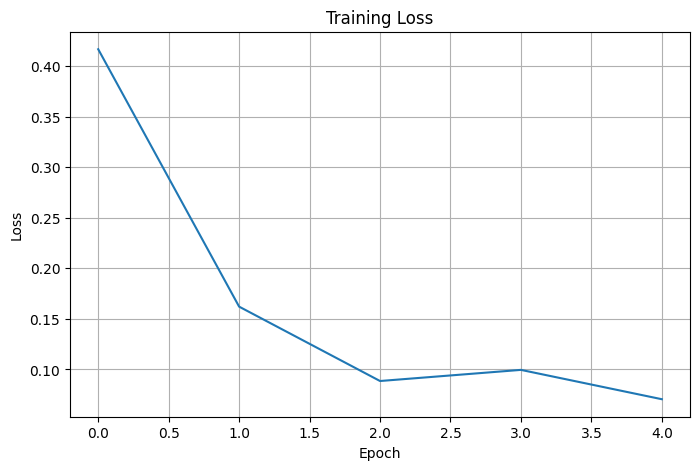

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_losses)

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

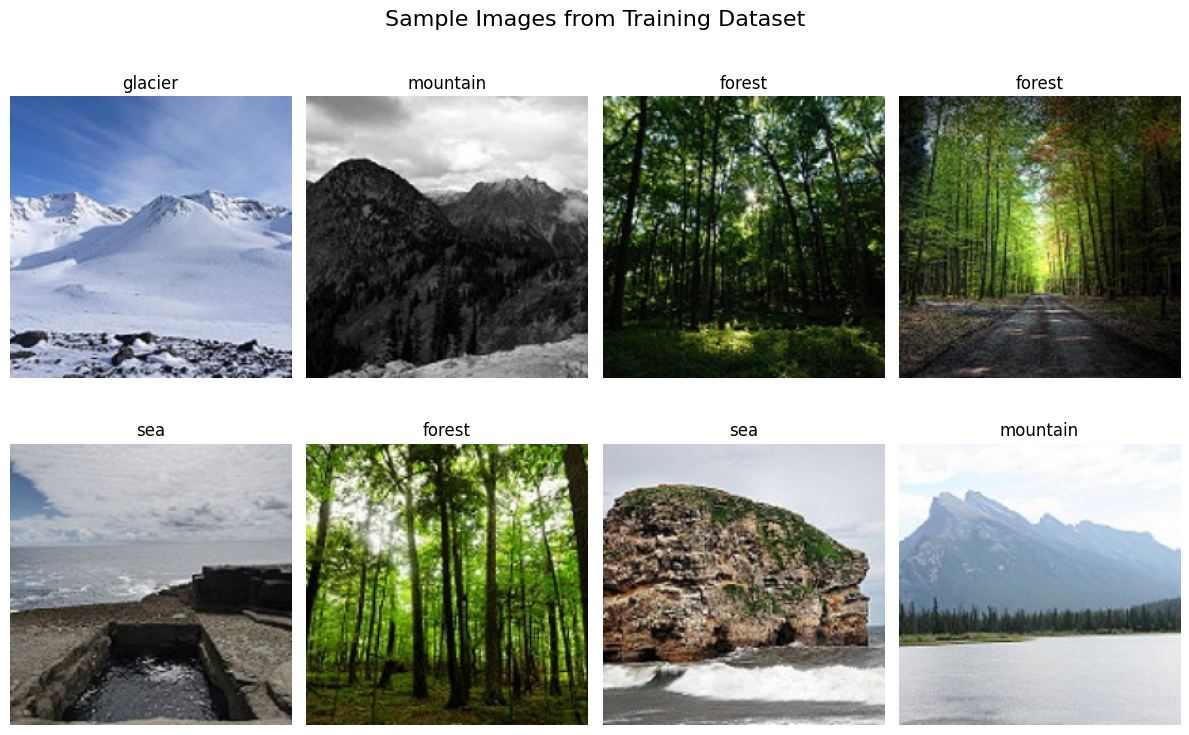

In [ ]:
# Visualize Sample Images from Training Dataset

import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

class_names = train_dataset.classes

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    # Convert image from (C,H,W) to (H,W,C)
    img = images[i].permute(1, 2, 0)

    plt.imshow(img)
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.suptitle("Sample Images from Training Dataset", fontsize=16)
plt.tight_layout()
plt.show()

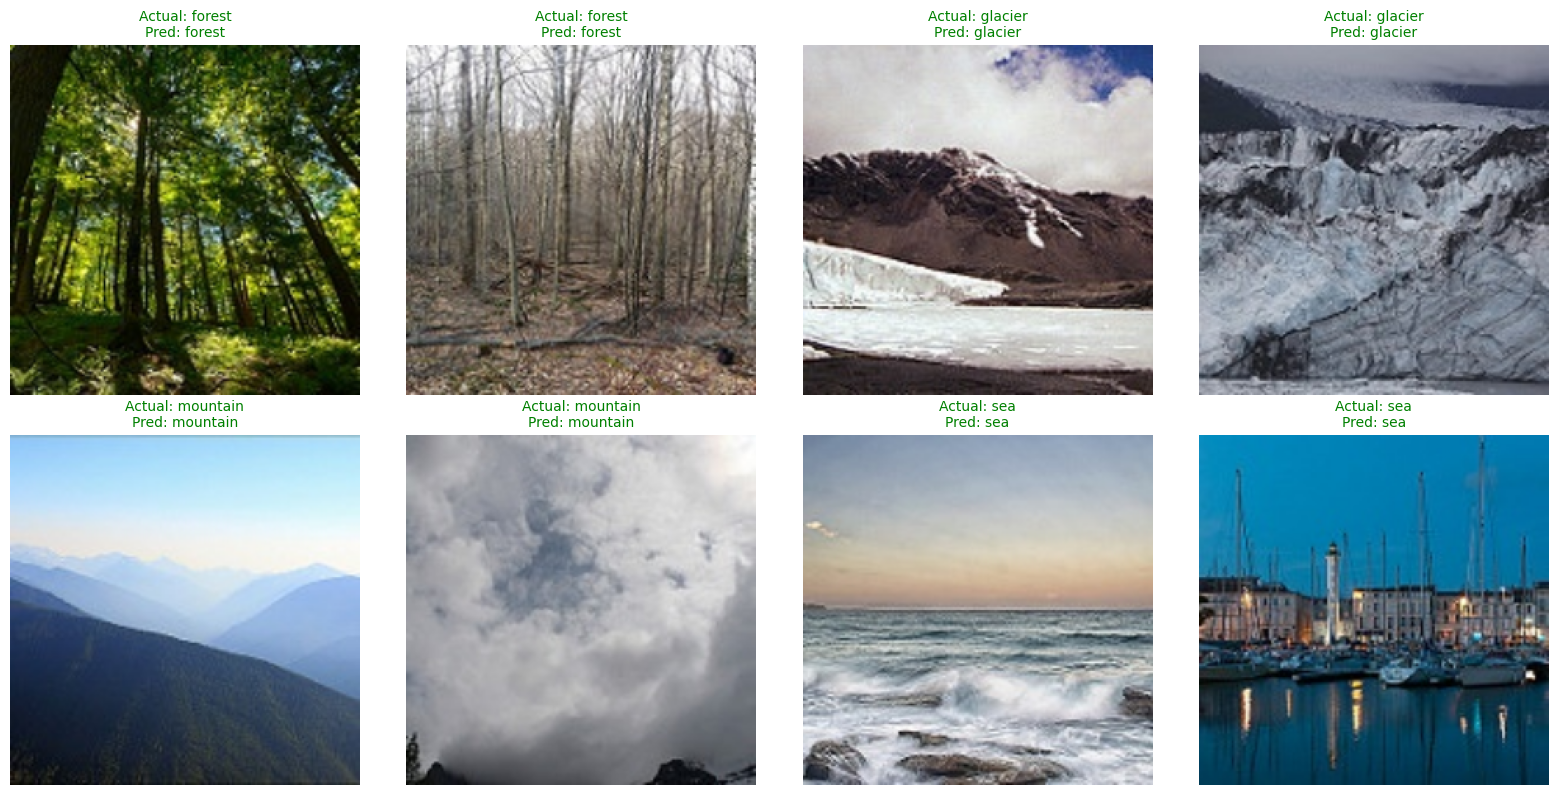

In [ ]:
import matplotlib.pyplot as plt
import random
import torch

model.eval()

class_names = test_dataset.classes

selected_samples = []

# Select 2 random images from each class
for class_idx in range(len(class_names)):

    indices = [
        i for i, (_, label) in enumerate(test_dataset.samples)
        if label == class_idx
    ]

    random.shuffle(indices)

    for idx in indices[:2]:

        image, label = test_dataset[idx]

        with torch.no_grad():
            output = model(image.unsqueeze(0).to(device))
            _, pred = torch.max(output, 1)

        selected_samples.append((image, label, pred.item()))

# Display 8 images
plt.figure(figsize=(16,8))

for i, (image, actual, predicted) in enumerate(selected_samples):

    plt.subplot(2,4,i+1)

    plt.imshow(image.permute(1,2,0))

    actual_name = class_names[actual]
    pred_name = class_names[predicted]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual_name}\nPred: {pred_name}",
        color=color,
        fontsize=10
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()


image_path = list(uploaded.keys())[0]


image = Image.open(image_path).convert("RGB")

input_image = test_transform(image).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(input_image)
    prediction = torch.argmax(output, dim=1).item()


classes = train_dataset.classes

predicted_class = classes[prediction]

Saving sea.jpg to sea.jpg


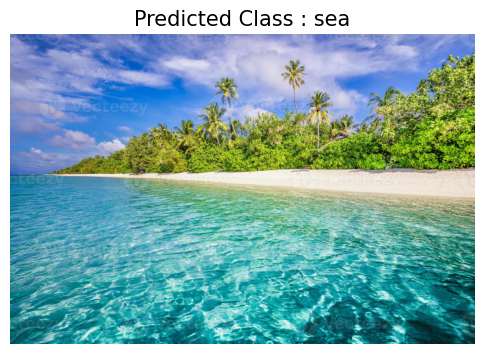

Predicted Class: sea


In [ ]:
plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis("off")
plt.title(f"Predicted Class : {predicted_class}", fontsize=15)
plt.show()

print("Predicted Class:", predicted_class)